# The night-sky spectrum

**What this notebook shows.** A forecast of an emission-line measurement needs the sky *at the line's wavelength*, not a single broadband number: the sky between the OH and O I lines is dark, on a line it is orders of magnitude brighter, and moonlight adds a smooth continuum that depends on the moon's phase, altitude and distance from the target.

`kino.observing.skymodel` provides that spectrum from ESO's Cerro Paranal Advanced Sky Model (Noll et al. 2012, A&A 543, A92; Jones et al. 2013, A&A 560, A91), evaluated once on a grid by `scripts/build_skycalc_library.py` and interpolated offline, so a batch run never touches the network and is bit-for-bit reproducible.

Components (all in photons s$^{-1}$ m$^{-2}$ $\mu$m$^{-1}$ arcsec$^{-2}$): **moonlight**, **airglow** (emission lines + residual continuum), **zodiacal light**, **scattered starlight**.

> **Needs the library.** Build it once with `python scripts/build_skycalc_library.py` (network, about 7 minutes). The cells below read it from `data/skycalc/`.

**Caveats that apply to every plot here:** the model is for Paranal (2640 m), not Pachon; it lacks La Serena's light pollution and Pachon's aerosols. Airglow is a whole-night, all-season average. Wavelengths are vacuum.

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from kino_style import AQUA, BLUE, INK2, ORANGE, SEQ_BLUES, YELLOW

from kino.instruments.ifu import IFU
from kino.observing import (
    NOAA_SWPC_F107_PREDICTION,
    SkyConditions,
    SkyLibrary,
    extinction_coefficient,
    ifu_sky_electron_rate,
    sky_brightness_v,
    solar_flux,
)

lib = SkyLibrary.load("../data/skycalc")
print(lib.meta.get("source"), "| built", lib.meta.get("built"))
print("library wavelength range:", lib.wavelength_range)

ESO SkyCalc (skycalc_cli), Cerro Paranal Advanced Sky Model | built 2026-09-26 16:50:13 UTC
library wavelength range: (<Quantity 320. nm>, <Quantity 1000. nm>)


## 1. The four components in the dark

Airmass 1.2, no moon, the NOAA-predicted solar flux for March 2027. The spectrum is binned to 0.5 nm channels, exactly as an instrument would see it: `bin_to_channels` integrates the piecewise-linear spectrum, so an unresolved line contributes its full flux to the channel containing it.

Airglow lines (the O I 557.7 nm line, the OH forest redward of 650 nm) tower over everything; between them the floor is set by airglow continuum and zodiacal light.

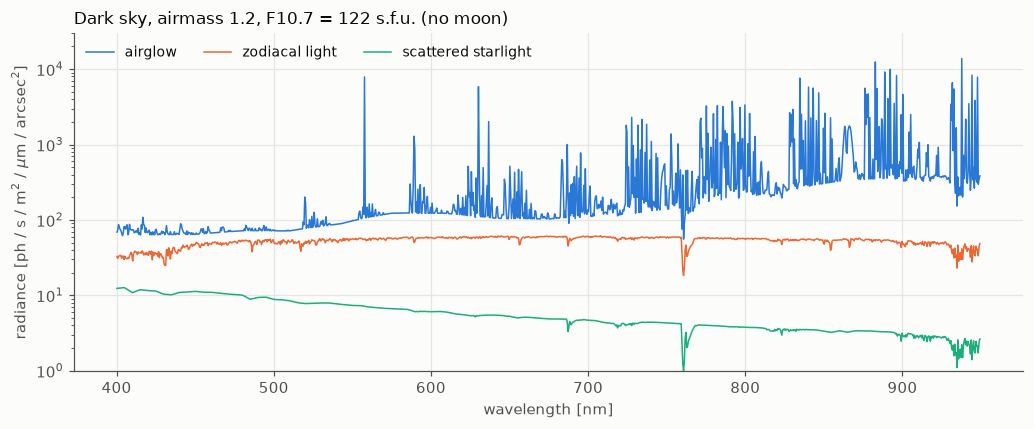

In [2]:
edges = np.arange(400.0, 950.0, 0.5) * u.nm
flux_mar27 = solar_flux("2027-03")[0]
dark = SkyConditions(airmass=1.2, solar_flux=flux_mar27)
sp = lib.spectrum(dark, edges)

fig, ax = plt.subplots(figsize=(9.5, 4.0))
labels = {
    "airglow": (BLUE, "airglow"),
    "zodiacal": (ORANGE, "zodiacal light"),
    "starlight": (AQUA, "scattered starlight"),
}
for key, (c, lab) in labels.items():
    ax.plot(sp.wavelength.value, sp.components[key], color=c, lw=1.0, label=lab)
ax.set_yscale("log")
ax.set_ylim(1, 3e4)
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("radiance [ph / s / m$^2$ / $\\mu$m / arcsec$^2$]")
ax.set_title(f"Dark sky, airmass 1.2, F10.7 = {flux_mar27:.0f} s.f.u. (no moon)")
ax.legend(loc="upper left", ncol=3)
fig.tight_layout()

## 2. What the moon adds

Moonlight is a smooth, roughly solar-coloured continuum (with the solar absorption lines imprinted). The three curves below use the same geometry (moon 40$^\circ$ from zenith, target 60$^\circ$ from the moon, airmass 1.2) at different phases. The dark-sky floor is the black line.

At a quarter moon the continuum around 650-700 nm is already comparable to the *dark* airglow-plus-zodiacal floor; at full moon it exceeds it by an order of magnitude, which is why the moon calendar matters as much as the airmass.

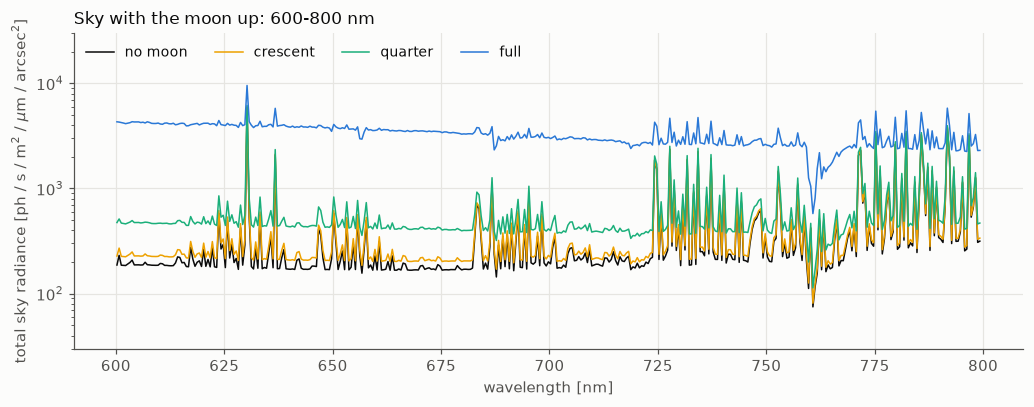

In [3]:
edges = np.arange(600.0, 800.0, 0.5) * u.nm
fig, ax = plt.subplots(figsize=(9.5, 3.8))
sp0 = lib.spectrum(dark, edges)
ax.plot(sp0.wavelength.value, sp0.total, color="#0b0b0b", lw=1.0, label="no moon")
for alpha, c, name in [(135, YELLOW, "crescent"), (90, AQUA, "quarter"), (0, BLUE, "full")]:
    cond = SkyConditions(
        1.2,
        flux_mar27,
        moon_phase_angle=alpha * u.deg,
        moon_target_separation=60 * u.deg,
        moon_zenith_distance=40 * u.deg,
    )
    ax.plot(sp0.wavelength.value, lib.spectrum(cond, edges).total, color=c, lw=1.0, label=name)
ax.set_yscale("log")
ax.set_ylim(30, 3e4)
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("total sky radiance [ph / s / m$^2$ / $\\mu$m / arcsec$^2$]")
ax.set_title("Sky with the moon up: 600-800 nm")
ax.legend(ncol=4, loc="upper left")
fig.tight_layout()

## 3. Does the library agree with independent references?

A model is only useful if it is anchored. Two independent checks in the V band (505-595 nm, a crude top-hat):

* **Dark sky** against the CTIO mean, $V=21.79\pm0.22$ mag arcsec$^{-2}$ (Krisciunas et al. 2007, Table 6, 1992-2006).
* **Moonlight** against the classic Krisciunas & Schaefer (1991) empirical model, at four phase/separation geometries: the *brightening* $\Delta V$ from the moon.

The two agree to a few tenths of a magnitude. K&S91 quote 8-23 % accuracy for their model, so differences of this size are inside the uncertainty of *both*.

dark zenith V (100 s.f.u.): 21.86; CTIO mean 21.79 +/- 0.22
alpha= 30 rho= 60: SkyCalc dV=-2.37  K&S dV=-2.32
alpha= 90 rho= 60: SkyCalc dV=-1.00  K&S dV=-0.95
alpha=  0 rho= 60: SkyCalc dV=-3.43  K&S dV=-3.04
alpha=  0 rho= 30: SkyCalc dV=-4.10  K&S dV=-3.75


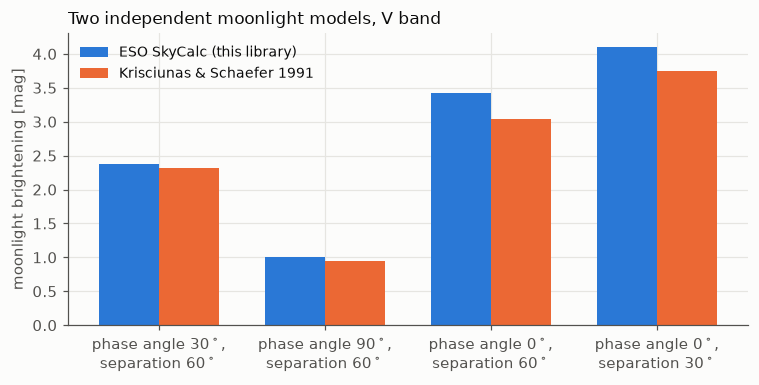

In [4]:
ZP = 3.631e-9 * 1e-7 * 1e4 * 1e4 / (6.62607e-34 * 2.99792458e8 / 550e-9)  # ph/s/m2/um for V = 0


def v_mag(cond):
    r = lib.spectrum(cond, np.array([505.0, 595.0]) * u.nm).total[0]
    return -2.5 * np.log10(r / ZP)


k_v = float(extinction_coefficient(5556 * u.AA)[0])
rows = []
for alpha, rho, zm in [(30, 60, 50), (90, 60, 50), (0, 60, 50), (0, 30, 40)]:
    z = 33.6
    x = 1 / np.cos(np.radians(z))
    base = SkyConditions(x, 100.0)
    moon = SkyConditions(
        x,
        100.0,
        moon_phase_angle=alpha * u.deg,
        moon_target_separation=rho * u.deg,
        moon_zenith_distance=zm * u.deg,
    )
    d_skycalc = v_mag(moon) - v_mag(base)
    d_ks = float(
        sky_brightness_v(21.79, alpha * u.deg, rho * u.deg, zm * u.deg, z * u.deg, k_v)["delta_v"]
    )
    rows.append((alpha, rho, d_skycalc, d_ks))

v_dark = v_mag(SkyConditions(1.0, 100.0))
print(f"dark zenith V (100 s.f.u.): {v_dark:.2f}; CTIO mean 21.79 +/- 0.22")
fig, ax = plt.subplots(figsize=(7.0, 3.6))
x = np.arange(len(rows))
w = 0.36
ax.bar(x - w / 2, [-r[2] for r in rows], w, color=BLUE, label="ESO SkyCalc (this library)")
ax.bar(x + w / 2, [-r[3] for r in rows], w, color=ORANGE, label="Krisciunas & Schaefer 1991")
ax.set_xticks(x, [f"phase angle {r[0]}$^\\circ$,\nseparation {r[1]}$^\\circ$" for r in rows])
ax.set_ylabel("moonlight brightening [mag]")
ax.set_title("Two independent moonlight models, V band")
ax.legend(loc="upper left")
fig.tight_layout()
for r in rows:
    print(f"alpha={r[0]:3d} rho={r[1]:3d}: SkyCalc dV={r[2]:+.2f}  K&S dV={r[3]:+.2f}")

## 4. Airglow and the solar cycle

Airglow brightens with solar activity (the 10.7 cm radio flux, F10.7). The library is built on a grid from 70 to 200 s.f.u.; NOAA's predicted monthly F10.7 for the months of the 2027A semester (from `kino.observing.solar`, retrieved 2026-09-26) falls from about 124 to 111 s.f.u., with a stated range of about 96-134. The shaded band is that range.

Over it the mean airglow radiance changes by only about 10 %. So the *solar flux is not a large uncertainty* for this semester; the moon is.

over 98-134 s.f.u. the mean airglow changes by 11%


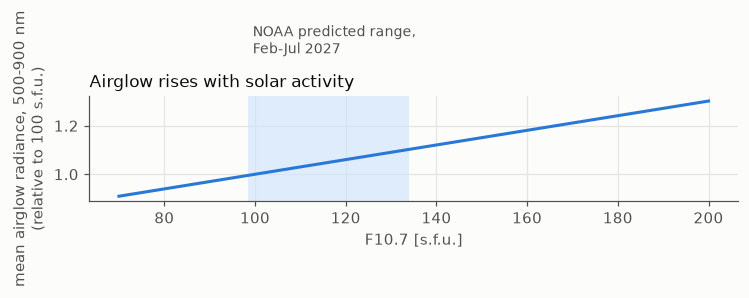

In [5]:
fluxes = np.linspace(70, 200, 27)
edges = np.array([500.0, 900.0]) * u.nm
mean_glow = np.array(
    [lib.spectrum(SkyConditions(1.2, f), edges).components["airglow"][0] for f in fluxes]
)

fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.plot(fluxes, mean_glow / mean_glow[np.argmin(abs(fluxes - 100))], color=BLUE)
months = [m for m in NOAA_SWPC_F107_PREDICTION if "2027-02" <= m <= "2027-07"]
lo = min(NOAA_SWPC_F107_PREDICTION[m][1] for m in months)
hi = max(NOAA_SWPC_F107_PREDICTION[m][2] for m in months)
ax.axvspan(lo, hi, color=SEQ_BLUES[0], alpha=0.6, lw=0)
ax.text(lo + 1, 1.62, "NOAA predicted range,\nFeb-Jul 2027", color=INK2, fontsize=9, va="top")
ax.set_xlabel("F10.7 [s.f.u.]")
ax.set_ylabel("mean airglow radiance, 500-900 nm\n(relative to 100 s.f.u.)")
ax.set_title("Airglow rises with solar activity")
fig.tight_layout()
a, b = (lib.spectrum(SkyConditions(1.2, f), edges).components["airglow"][0] for f in (lo, hi))
change = 100 * (b / a - 1)
print(f"over {lo:.0f}-{hi:.0f} s.f.u. the mean airglow changes by {change:.0f}%")

## 5. What it means for an IFU: sky against read noise

`ifu_sky_electron_rate(ifu, conditions, library)` turns the sky spectrum into detected electrons per second per spaxel per channel, on the *same* collecting area and throughput the source uses. For the SOAR SIFS configuration (0.3 arcsec fibres, 0.69 A per pixel) in a 200 A window, and a one-hour exposure:

* **Dark and grey time: read-noise limited.** The sky contributes only a few electrons per channel against about 46 (variance) from three 3.9 e$^-$ reads.
* **Near full moon: sky-limited.** The sky variance passes the read-noise variance.

That is a concrete scheduling result: for SIFS, a moonless night is worth a lot only if the *target* is faint; when the source dominates, or the moon is far and low, the difference is small. (The median is shown; the OH lines redward of 700 nm are much brighter in individual channels.)

dark     :     3.4 e- per channel  (sky/read variance = 0.07)
crescent :     4.1 e- per channel  (sky/read variance = 0.09)
quarter  :     7.8 e- per channel  (sky/read variance = 0.17)
gibbous  :    18.2 e- per channel  (sky/read variance = 0.40)
full     :    58.8 e- per channel  (sky/read variance = 1.29)


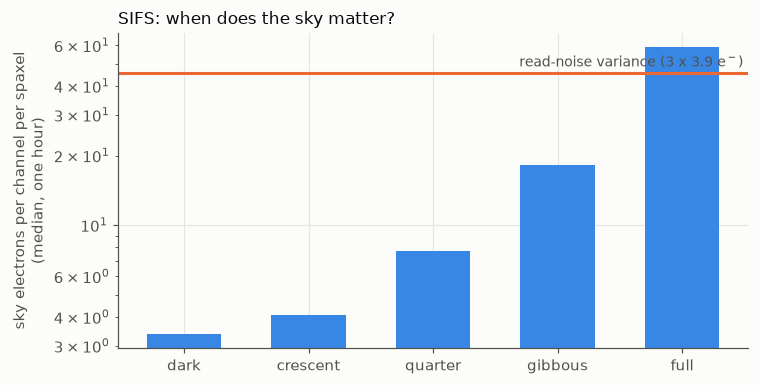

In [6]:
ifu = IFU.from_config("../kino/config/sifs.yaml")
total_exposure = (ifu.exposure_time * ifu.n_exposures).to_value(u.s)
read_var = ifu.detector.read_noise.to_value(u.electron) ** 2 * ifu.n_exposures

cases = [
    ("dark", SkyConditions(1.3, flux_mar27)),
    (
        "crescent",
        SkyConditions(
            1.3,
            flux_mar27,
            moon_phase_angle=135 * u.deg,
            moon_target_separation=60 * u.deg,
            moon_zenith_distance=45 * u.deg,
        ),
    ),
    (
        "quarter",
        SkyConditions(
            1.3,
            flux_mar27,
            moon_phase_angle=90 * u.deg,
            moon_target_separation=60 * u.deg,
            moon_zenith_distance=45 * u.deg,
        ),
    ),
    (
        "gibbous",
        SkyConditions(
            1.3,
            flux_mar27,
            moon_phase_angle=45 * u.deg,
            moon_target_separation=60 * u.deg,
            moon_zenith_distance=45 * u.deg,
        ),
    ),
    (
        "full",
        SkyConditions(
            1.3,
            flux_mar27,
            moon_phase_angle=0 * u.deg,
            moon_target_separation=60 * u.deg,
            moon_zenith_distance=45 * u.deg,
        ),
    ),
]
sky_e = [
    float(np.median(ifu_sky_electron_rate(ifu, c, lib).value)) * total_exposure for _, c in cases
]

fig, ax = plt.subplots(figsize=(7.0, 3.6))
names = [n for n, _ in cases]
ax.bar(names, sky_e, color=SEQ_BLUES[3], width=0.6)
ax.axhline(read_var, color=ORANGE, lw=2)
ax.text(
    len(names) - 0.5,
    read_var * 1.06,
    "read-noise variance (3 x 3.9 e$^-$)",
    color=INK2,
    ha="right",
    fontsize=9,
)
ax.set_yscale("log")
ax.set_ylabel("sky electrons per channel per spaxel\n(median, one hour)")
ax.set_title("SIFS: when does the sky matter?")
fig.tight_layout()
for n, e in zip(names, sky_e, strict=False):
    print(f"{n:9s}: {e:7.1f} e- per channel  (sky/read variance = {e / read_var:.2f})")

## Limits and what comes next

* Paranal, not Pachon: light pollution and aerosols are missing. A Pachon-specific correction (or a measured sky spectrum from SOAR itself) would sharpen this.
* Airglow varies through the night and with season by tens of percent; the library holds the whole-night, all-season mean.
* Near-infrared (Gemini NIR, TripleSpec) needs the library extended beyond 1 $\mu$m and a near-infrared extinction curve.
* Next: `notebooks/10_sifs_forecast.ipynb` combines all of this with an instrument and a galaxy to give shear S/N as a function of seeing.